# Previsão diária de aluguéis com LSTM
**Equipe:** Felipe Vieira Brazão e João Ricardo Almeida  
**Disciplina:** Inteligência Computacional / Machine Learning  
**Professora:** Polyana Santos Fonseca Nascimento

## Transparência no uso de IA generativa
Foi utilizado o ChatGPT/Codex, da OpenAI, para  pesquisar a fonte dos dados , elaborar a estrutura, os textos e suporte no código deste notebook. A equipe realizou a função de revisar, executar e compreender o material antes da entrega. Foram feitas verificações de sintaxe e do protocolo de separação temporal; a execução completa do treinamento e a conferência dos resultados pela dupla. Não se apresentam métricas inventadas.

**Como executar:** abra este arquivo no Google Colab (Arquivo > Fazer upload de notebook) e use Ambiente de execução > Executar tudo. A primeira execução requer internet para baixar a base. Se necessário, instale as dependências indicadas na primeira célula. Salve a versão com todas as saídas. É obrigatório participar de pelo menos um encontro de acompanhamento antes da entrega; registrem a data real após participar.

## 1. Ambiente e reprodutibilidade
Usamos TensorFlow/Keras, NumPy, pandas e Matplotlib, normalmente disponíveis no Colab. Se um import falhar, executem em uma célula: `%pip install tensorflow numpy pandas matplotlib`. As versões efetivas são registradas abaixo. A semente reduz variações, mas hardware e versões podem afetar o treinamento.

**Execução local no Windows:** selecione o kernel **Python (LSTM - projeto)**, que usa o ambiente `.venv` desta pasta. Para executar tudo pelo terminal, use `.\.venv\Scripts\python.exe executar_notebook.py`. As tabelas, os gráficos e as conclusões ficam salvos nas saídas deste notebook. Não são gerados arquivos de resultados separados.

In [1]:
import os, io, zipfile, urllib.request, hashlib
from pathlib import Path
os.environ['TF_DETERMINISTIC_OPS'] = '1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown
SEED=42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

versoes={'tensorflow':tf.__version__, 'numpy':np.__version__, 'pandas':pd.__version__}
print(versoes)

{'tensorflow': '2.21.0', 'numpy': '2.5.4', 'pandas': '3.1.1'}


## 2. Dataset, problema e variável-alvo
Utilizamos o arquivo **day.csv**, do [Bike Sharing Dataset da UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), de Hadi Fanaee-T. A série registra aluguéis diários do sistema Capital Bikeshare em 2011 e 2012. O alvo é **cnt**, total de aluguéis por dia. O objetivo é prever o total do próximo dia, com horizonte de um passo. O experimento inicial usa apenas totais anteriores; a seção 7 acrescenta informações de calendário conhecidas antecipadamente.

A base permite estudar dependências temporais em um problema de mobilidade. O uso exclusivo do histórico evita depender de informações meteorológicas futuras. As colunas casual e registered não entram no modelo: sua soma compõe o alvo do próprio dia. A frequência é diária. A referência semanal é uma hipótese justificável pela diferença entre dias úteis e fins de semana; não se pressupõe que seja superior à persistência.

SHA256 day.csv: a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be
Observações: 731 | Período: 2011-01-01 00:00:00 a 2012-12-31 00:00:00


,Aluguéis por dia
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


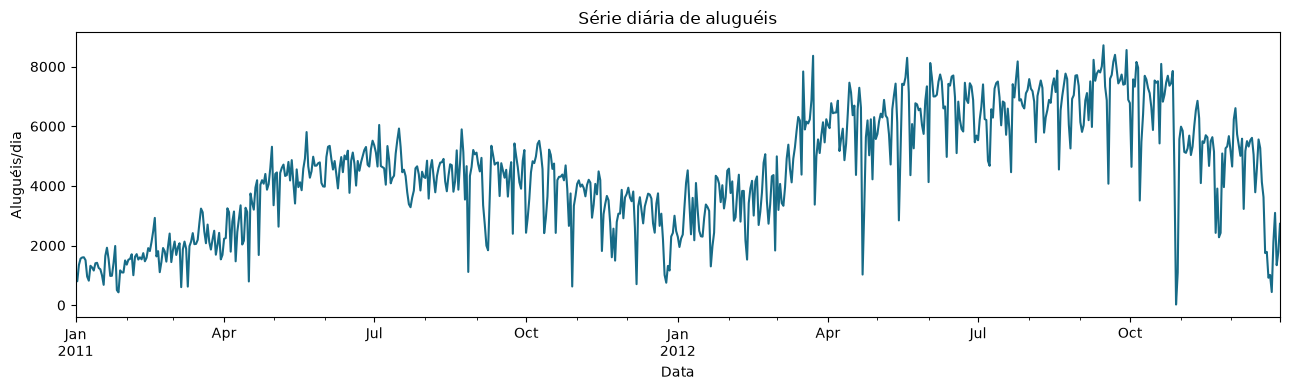

In [2]:
URL='https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
arquivo=Path('day.csv')
if not arquivo.exists():
    with urllib.request.urlopen(URL, timeout=90) as r:
        conteudo=r.read()
    with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
        nome=next(n for n in z.namelist() if n.split('/')[-1]=='day.csv')
        arquivo.write_bytes(z.read(nome))
print('SHA256 day.csv:',hashlib.sha256(arquivo.read_bytes()).hexdigest())
df=pd.read_csv(arquivo,parse_dates=['dteday']).sort_values('dteday')
assert not df['dteday'].duplicated().any(), 'Datas duplicadas: investigar antes de continuar.'
serie=df.set_index('dteday')['cnt'].asfreq('D')
assert serie.notna().all(), 'Há lacunas: investigar sem interpolar com dados futuros.'
assert (serie>=0).all()
print('Observações:',len(serie),'| Período:',serie.index.min(), 'a',serie.index.max())
display(serie.describe().to_frame('Aluguéis por dia'))
fig,ax=plt.subplots(figsize=(13,4))
serie.plot(ax=ax,color='#176b87',title='Série diária de aluguéis')
ax.set(xlabel='Data',ylabel='Aluguéis/dia'); plt.tight_layout(); plt.show()

### Ordem cronológica e lacunas
Ordenamos as datas e verificamos duplicatas, valores ausentes e ausência de dias no calendário. O arquivo original deve passar nessas verificações sem imputação. Caso a fonte seja alterada e apareçam lacunas, o código interrompe a execução para investigação; não utiliza interpolação que consulte valores futuros.

## 3. Partições e normalização
Reservamos os últimos 20% da série (arredondados para cima) para teste, os 20% anteriores para validação e o início para treino. As partições usam a **data do alvo**. Os primeiros 28 dias fornecem contexto e não são alvos em nenhuma das duas configurações. Assim, todas as datas-alvo de treino, validação e teste são idênticas para as janelas de 7 e 28 dias.

A padronização usa média e desvio padrão somente do trecho de treino, incluindo seu contexto inicial. As previsões são reconvertidas a aluguéis/dia antes de calcular o MAE. Um alvo de validação ou teste pode usar observações reais anteriores já disponíveis: a avaliação representa previsões diárias sucessivas de um passo, com atualização do histórico, e não uma previsão de todo o período de uma só vez.

In [3]:
JANELAS=(7,28)
valores=serie.to_numpy(dtype=np.float32)
n=len(valores); n_teste=int(np.ceil(0.20*n)); n_val=int(np.ceil(0.20*n))
fim_treino=n-n_val-n_teste; inicio_teste=n-n_teste
assert fim_treino>max(JANELAS)
alvos=np.arange(max(JANELAS),n)
mascaras={'treino':alvos<fim_treino,
          'validacao':(alvos>=fim_treino)&(alvos<inicio_teste),
          'teste':alvos>=inicio_teste}
media=float(valores[:fim_treino].mean())
desvio=float(valores[:fim_treino].std())
assert desvio>0
z=(valores-media)/desvio
def criar_janelas(w):
    X=np.stack([z[t-w:t] for t in alvos])[...,None]
    y=z[alvos]
    assert X.shape==(len(alvos),w,1)
    return {p:(X[m],y[m]) for p,m in mascaras.items()}
dados={w:criar_janelas(w) for w in JANELAS}
resumo=[]
for p,m in mascaras.items():
    datas=serie.index[alvos[m]]
    resumo.append({'particao':p,'alvos':len(datas),'inicio':str(datas.min().date()),'fim':str(datas.max().date())})
    assert len(dados[7][p][1])==len(dados[28][p][1])
    np.testing.assert_array_equal(dados[7][p][1],dados[28][p][1])
assert mascaras['teste'].sum()/n>=0.20
display(pd.DataFrame(resumo))

,particao,alvos,inicio,fim
0,treino,409,2011-01-29,2012-03-12
1,validacao,147,2012-03-13,2012-08-06
2,teste,147,2012-08-07,2012-12-31


## 4. Janelas e arquitetura LSTM
A janela de **7 dias** contém uma semana; a de **28 dias**, quatro semanas. Ambas avançam um dia de cada vez. Para prever o dia t, a entrada termina em t-1; o valor do dia t nunca entra na própria entrada. A janela é deslizante de tamanho fixo, conforme a distinção do material de apoio, e não crescente.

Mantemos a mesma arquitetura: LSTM de 32 unidades, camada densa de 16 unidades com ReLU e saída linear de uma unidade. O otimizador é Adam (0,001), a perda é MAE, o lote é 32, o limite é 100 épocas e a parada antecipada tem paciência de 12 épocas, restaurando os melhores pesos. O número efetivo de épocas pode variar pela mesma regra de parada. Não embaralhamos os exemplos. Não reajustamos a configuração após consultar o teste.

In [4]:
def modelo_lstm(w):
    modelo=tf.keras.Sequential([
        tf.keras.Input(shape=(w,1)),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16,activation='relu'),
        tf.keras.layers.Dense(1)])
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='mae')
    return modelo
def mae(real,pred):
    return float(np.mean(np.abs(np.asarray(real)-np.asarray(pred))))
modelos={}; historicos={}; linhas=[]
for w in JANELAS:
    tf.keras.utils.set_random_seed(SEED)
    modelo=modelo_lstm(w)
    Xtr,ytr=dados[w]['treino']; Xv,yv=dados[w]['validacao']
    parada=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=12,restore_best_weights=True)
    hist=modelo.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=100,batch_size=32,
                    shuffle=False,callbacks=[parada],verbose=0)
    pred=modelo.predict(Xv,verbose=0).ravel()*desvio+media
    linhas.append({'janela_dias':w,'MAE_validacao':mae(valores[alvos[mascaras['validacao']]],pred),
                   'epocas':len(hist.history['loss'])})
    modelos[w]=modelo; historicos[w]=hist.history
    print('Treinamento concluído:',w,'dias')
tabela_val=pd.DataFrame(linhas).sort_values(['MAE_validacao','janela_dias']).reset_index(drop=True)
escolhida=int(tabela_val.iloc[0]['janela_dias'])
tabela_val['escolhida']=tabela_val['janela_dias'].eq(escolhida)
display(tabela_val)

print('Janela escolhida exclusivamente pela validação:',escolhida)

Treinamento concluído: 7 dias


Treinamento concluído: 28 dias


,janela_dias,MAE_validacao,epocas,escolhida
0,7,1342.928955,20,True
1,28,1405.344360,33,False


Janela escolhida exclusivamente pela validação: 7


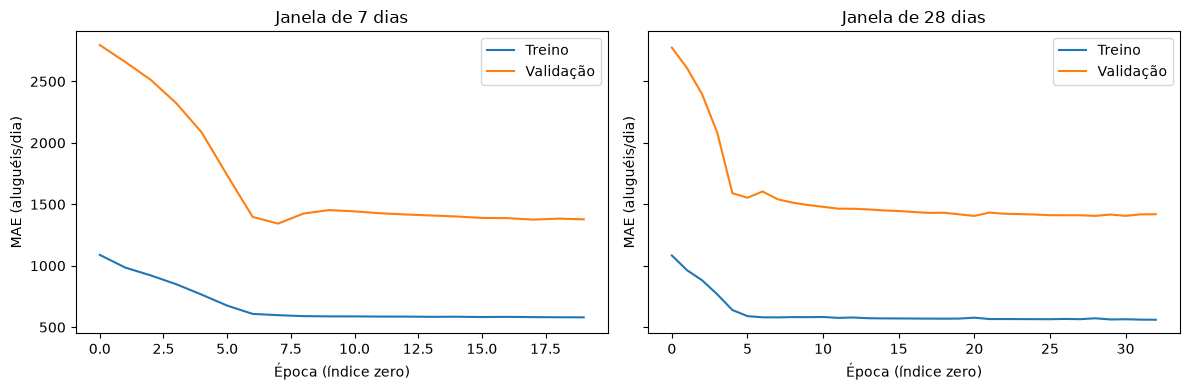

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,w in zip(axes,JANELAS):
    ax.plot(np.array(historicos[w]['loss'])*desvio,label='Treino')
    ax.plot(np.array(historicos[w]['val_loss'])*desvio,label='Validação')
    ax.set(title=f'Janela de {w} dias',xlabel='Época (índice zero)',ylabel='MAE (aluguéis/dia)')
    ax.legend()
plt.tight_layout(); plt.show()

## 5. Teste: LSTM selecionada e referências
Usamos o modelo selecionado sem novo treinamento. A **persistência** prevê y(t-1); a **referência semanal** prevê y(t-7). Todas são avaliadas nas mesmas datas e na escala original. Não arredondamos nem cortamos as previsões da LSTM. O MAE expressa o desvio absoluto médio em aluguéis diários; quanto menor, melhor.

,metodo,MAE_teste
1,Persistência,878.394531
2,Sazonal semanal,1194.734741
0,LSTM,1481.338867


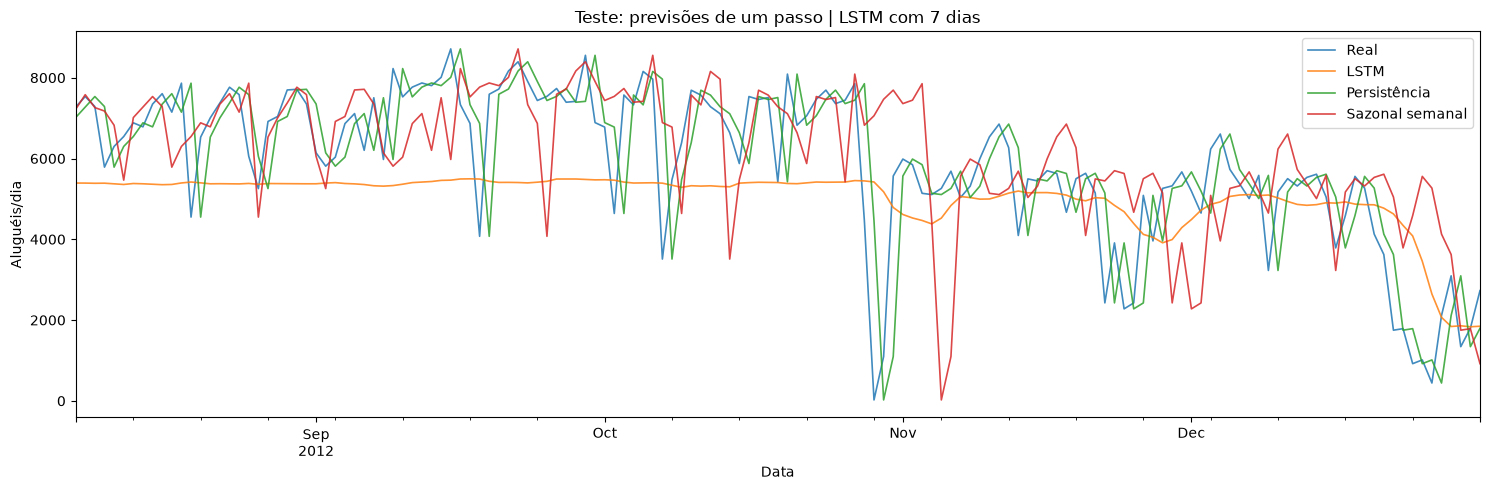

In [6]:
idx=alvos[mascaras['teste']]
Xt,_=dados[escolhida]['teste']
previsoes=pd.DataFrame({'Real':valores[idx],
    'LSTM':modelos[escolhida].predict(Xt,verbose=0).ravel()*desvio+media,
    'Persistência':valores[idx-1], 'Sazonal semanal':valores[idx-7]},index=serie.index[idx])
tabela_teste=pd.DataFrame([{'metodo':m,'MAE_teste':mae(previsoes['Real'],previsoes[m])}
    for m in previsoes.columns if m!='Real']).sort_values('MAE_teste')
display(tabela_teste)
fig,ax=plt.subplots(figsize=(15,5))
previsoes.plot(ax=ax,linewidth=1.2,alpha=0.85)
ax.set(title=f'Teste: previsões de um passo | LSTM com {escolhida} dias',xlabel='Data',ylabel='Aluguéis/dia')
plt.tight_layout(); plt.show()

## 6. Conclusão baseada nos resultados
A próxima célula produz uma síntese numérica a partir da execução real. A dupla deve complementá-la com a leitura do gráfico: os picos foram acompanhados? Houve atraso nas mudanças? Quais intervalos concentraram erros? Uma janela maior não garante melhor desempenho, e uma rede mais complexa pode perder para referências simples. O experimento usa uma única divisão cronológica e uma semente; portanto, não demonstra superioridade geral nem mede estabilidade estatística.

In [7]:
v=tabela_val.set_index('janela_dias')['MAE_validacao']
t=tabela_teste.set_index('metodo')['MAE_teste']
efeito='reduziu' if v.loc[28]<v.loc[7] else ('aumentou' if v.loc[28]>v.loc[7] else 'não alterou')
texto=f'A janela de 28 dias {efeito} o MAE de validação: 7 dias = {v.loc[7]:.2f}; 28 dias = {v.loc[28]:.2f} aluguéis/dia. A janela selecionada foi de {escolhida} dias.'
for ref in ['Persistência','Sazonal semanal']:
    rel='menor' if t['LSTM']<t[ref] else ('maior' if t['LSTM']>t[ref] else 'igual')
    texto+=f' No teste, o MAE da LSTM ({t["LSTM"]:.2f}) foi {rel} que o de {ref} ({t[ref]:.2f}).'
display(Markdown(texto))

A janela de 28 dias aumentou o MAE de validação: 7 dias = 1342.93; 28 dias = 1405.34 aluguéis/dia. A janela selecionada foi de 7 dias. No teste, o MAE da LSTM (1481.34) foi maior que o de Persistência (878.39). No teste, o MAE da LSTM (1481.34) foi maior que o de Sazonal semanal (1194.73).

## 7. Features: análise empírica e modelo escolhido
Usamos uma análise empírica para definir uma versão multivariada simples: **histórico de `cnt`, dia da semana e feriado**, com janela de **7 dias**. A escolha considera o padrão semanal de deslocamentos e a possibilidade de alteração da demanda nos feriados. A comparação final verifica seu comportamento frente à LSTM original.

O dia da semana é representado por seis indicadores, tomando segunda-feira como referência; feriado é um indicador binário. Com `cnt`, são **8 features por passo**. Em cada passo histórico anexamos o calendário do dia seguinte; assim, o último passo contém o dia da semana e o feriado do alvo, informações já conhecidas no momento da previsão. Os valores de `cnt` são sempre anteriores ao alvo.

O heatmap abaixo é uma análise exploratória calculada apenas no treino. Correlação baixa não elimina a possibilidade de um efeito localizado, como o de feriado. Temperatura e sensação térmica são muito semelhantes; a versão apresentada usa apenas o calendário e o histórico de aluguéis, sem clima. `casual`, `registered`, `instant` e o clima observado do dia previsto são excluídos.

Apresentamos a configuração escolhida e seus resultados, sem reproduzir a busca de combinações nem repetir o treinamento em várias sementes. Todas as redes usam a semente 42. A separação cronológica entre treino, validação e teste permanece; a validação orienta a parada antecipada e o teste é usado para a comparação final. As escolhas foram feitas durante a exploração destes dados, portanto os resultados não constituem uma avaliação independente de novos dados.


C:\Users\PC\AppData\Local\Temp\ipykernel_29984\1493149769.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  'semana_sin':np.sin(2*np.pi*datas.dayofweek/7),
C:\Users\PC\AppData\Local\Temp\ipykernel_29984\1493149769.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  'semana_cos':np.cos(2*np.pi*datas.dayofweek/7),
C:\Users\PC\AppData\Local\Temp\ipykernel_29984\1493149769.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  'ano_sin':np.sin(2*np.pi*(datas.dayofyear-1)/365.25),
C:\Users\PC\AppData\Local\Temp\ipykernel_29984\1493149769.py:9: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  'ano_cos':np.cos(2*np.pi*(datas.dayofyear-1)/365.2

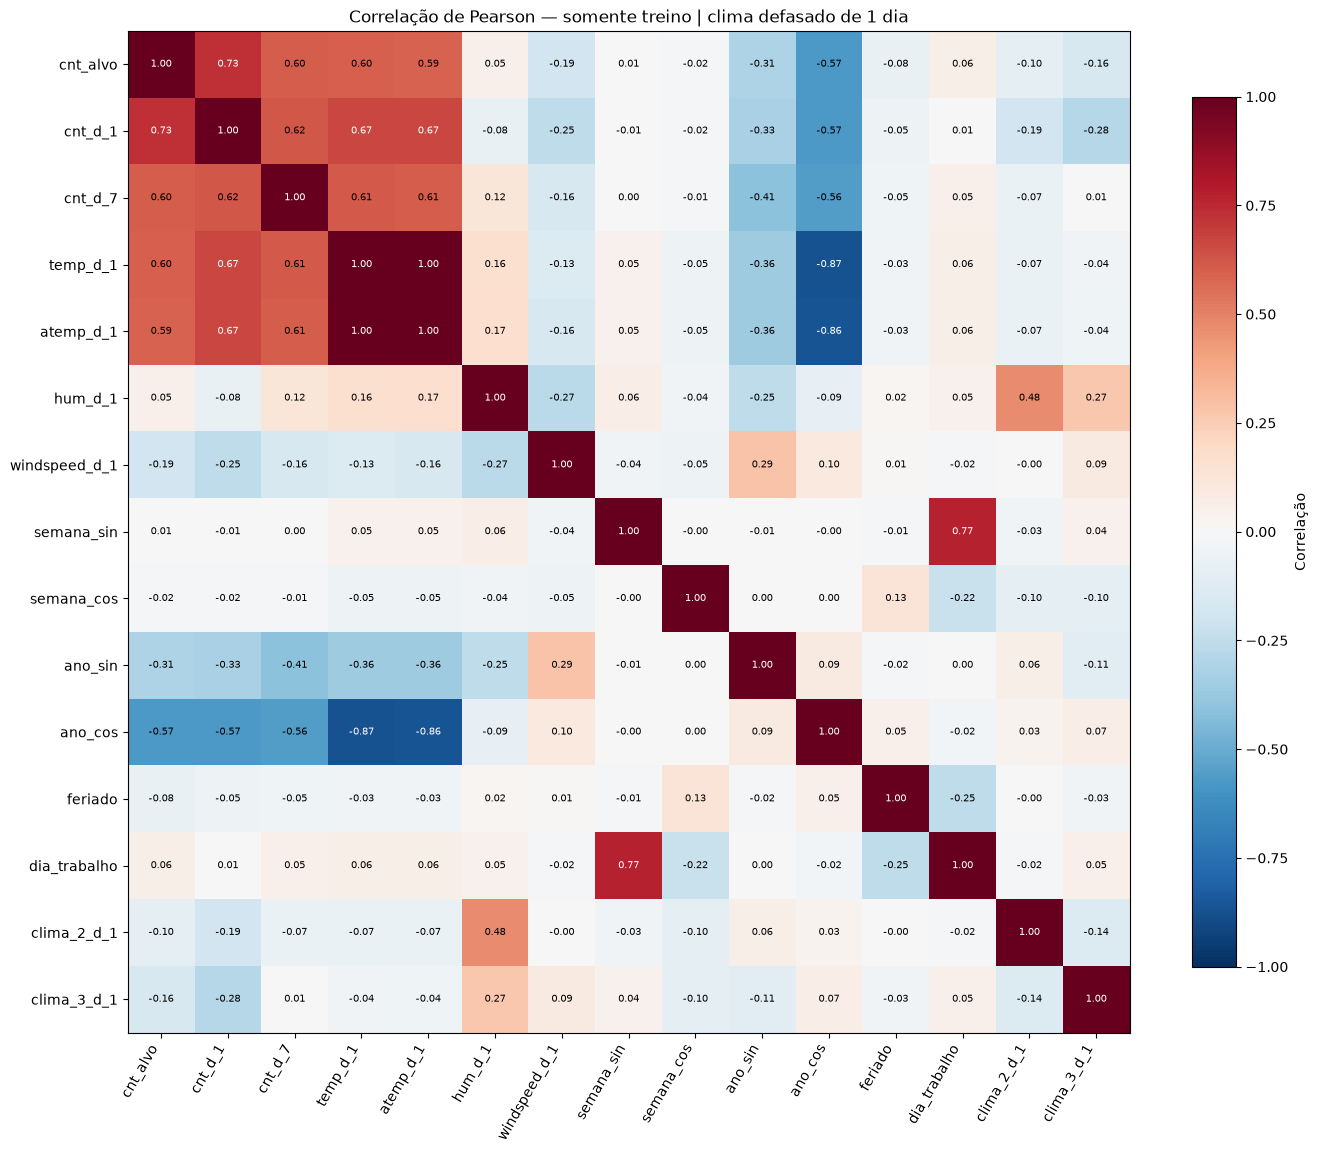

,correlacao_com_alvo
cnt_d_1,0.733107
cnt_d_7,0.604461
temp_d_1,0.596129
atemp_d_1,0.592457
ano_cos,-0.570809
ano_sin,-0.312340
windspeed_d_1,-0.187800
clima_3_d_1,-0.160114
clima_2_d_1,-0.101259
feriado,-0.076654


Constantes omitidas do heatmap: ['clima_4_d_1']
Correlação temp/atemp passadas: 0.9962240737130482


In [8]:
base=df.set_index('dteday').reindex(serie.index)
assert base[['cnt','temp','atemp','hum','windspeed','weathersit','holiday','workingday']].notna().all().all()
assert np.array_equal(base['cnt'].to_numpy(),valores)
datas=serie.index
calendario=pd.DataFrame({
    'semana_sin':np.sin(2*np.pi*datas.dayofweek/7),
    'semana_cos':np.cos(2*np.pi*datas.dayofweek/7),
    'ano_sin':np.sin(2*np.pi*(datas.dayofyear-1)/365.25),
    'ano_cos':np.cos(2*np.pi*(datas.dayofyear-1)/365.25),
    'feriado':base['holiday'],
    'dia_trabalho':base['workingday']},index=datas).astype('float32')
# Todos os preditores abaixo estariam disponíveis ao prever o dia do índice.
analise=pd.DataFrame({'cnt_alvo':valores,
                      'cnt_d_1':base['cnt'].shift(1),
                      'cnt_d_7':base['cnt'].shift(7)},index=datas)
for c in ['temp','atemp','hum','windspeed']:
    analise[c+'_d_1']=base[c].shift(1)
# Categorias fixadas pelo esquema da base, sem aprender categorias do teste.
clima_cat=pd.DataFrame({f'clima_{k}':(base['weathersit']==k).astype('float32')
                        for k in (2,3,4)},index=datas)
analise=pd.concat([analise,calendario,clima_cat.shift(1).add_suffix('_d_1')],axis=1)
analise_treino=analise.iloc[alvos[mascaras['treino']]]
assert analise_treino.notna().all().all()
# Variáveis constantes no treino não têm correlação definida.
constantes=analise_treino.columns[analise_treino.nunique()<=1].tolist()
correlacao=analise_treino.drop(columns=constantes).corr(method='pearson')

fig,ax=plt.subplots(figsize=(14,12))
im=ax.imshow(correlacao,vmin=-1,vmax=1,cmap='RdBu_r')
rotulos=correlacao.columns.tolist()
ax.set_xticks(range(len(rotulos)),rotulos,rotation=60,ha='right')
ax.set_yticks(range(len(rotulos)),rotulos)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        r=correlacao.iloc[i,j]
        ax.text(j,i,f'{r:.2f}',ha='center',va='center',fontsize=7,
                color='white' if abs(r)>0.65 else 'black')
ax.set_title('Correlação de Pearson — somente treino | clima defasado de 1 dia')
fig.colorbar(im,ax=ax,label='Correlação',shrink=0.8)
fig.tight_layout()

plt.show()
display(correlacao['cnt_alvo'].drop('cnt_alvo').sort_values(key=abs,ascending=False).to_frame('correlacao_com_alvo'))
print('Constantes omitidas do heatmap:',constantes)
print('Correlação temp/atemp passadas:',correlacao.loc['temp_d_1','atemp_d_1'])

### Preparação das features
Cada coluna é padronizada com média e desvio calculados somente no trecho de treino. O alvo mantém a escala do experimento original. Usamos as mesmas datas-alvo das redes univariadas e verificamos que o último passo contém `cnt` de ontem e o calendário do dia previsto.


In [9]:
w_features=7
semana=pd.DataFrame({f'semana_{k}_seguinte':(datas.dayofweek==k).astype('float32')
                    for k in range(1,7)},index=datas).shift(-1)
feriado=base[['holiday']].shift(-1).rename(columns={'holiday':'feriado_seguinte'})
features=pd.concat([base[['cnt']],semana,feriado],axis=1).astype('float32')
# Mesmas linhas de referência do treino usadas na preparação anterior.
linhas_treino=np.unique(np.concatenate([np.arange(t-max(JANELAS),t)
                                      for t in alvos[mascaras['treino']]]))
medias_features=features.iloc[linhas_treino].mean()
desvios_features=features.iloc[linhas_treino].std(ddof=0)
assert (desvios_features>0).all()
matriz_features=((features-medias_features)/desvios_features).to_numpy(dtype=np.float32)
X_features=np.stack([matriz_features[t-w_features:t] for t in alvos])
assert X_features.shape==(len(alvos),w_features,8)
assert np.isfinite(X_features).all()
np.testing.assert_array_equal(features['cnt'].iloc[alvos-1],valores[alvos-1])
np.testing.assert_array_equal(features['feriado_seguinte'].iloc[alvos-1],base['holiday'].iloc[alvos])
dados_features={p:(X_features[m],z[alvos[m]]) for p,m in mascaras.items()}
for particao in mascaras:
    np.testing.assert_array_equal(dados_features[particao][1],dados[7][particao][1])
display(pd.DataFrame({'feature':features.columns,
    'papel':['Histórico de aluguéis']+['Calendário conhecido do dia previsto']*7}))


C:\Users\PC\AppData\Local\Temp\ipykernel_29984\4207009542.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  semana=pd.DataFrame({f'semana_{k}_seguinte':(datas.dayofweek==k).astype('float32')
C:\Users\PC\AppData\Local\Temp\ipykernel_29984\4207009542.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  semana=pd.DataFrame({f'semana_{k}_seguinte':(datas.dayofweek==k).astype('float32')
C:\Users\PC\AppData\Local\Temp\ipykernel_29984\4207009542.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  semana=pd.DataFrame({f'semana_{k}_seguinte':(datas.dayofweek==k).astype('float32')
C:\Users\PC\AppData\Local\Temp\ipykernel_29984\4207009542.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future v

,feature,papel
0,cnt,Histórico de aluguéis
1,semana_1_seguinte,Calendário conhecido do dia previsto
2,semana_2_seguinte,Calendário conhecido do dia previsto
3,semana_3_seguinte,Calendário conhecido do dia previsto
4,semana_4_seguinte,Calendário conhecido do dia previsto
5,semana_5_seguinte,Calendário conhecido do dia previsto
6,semana_6_seguinte,Calendário conhecido do dia previsto
7,feriado_seguinte,Calendário conhecido do dia previsto


In [10]:
tf.keras.utils.set_random_seed(SEED)
modelo_features=tf.keras.Sequential([
    tf.keras.Input(shape=(w_features,X_features.shape[-1])),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(1)])
modelo_features.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='mae')
Xtr_features,ytr_features=dados_features['treino']
Xv_features,yv_features=dados_features['validacao']
parada=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=12,restore_best_weights=True)
hist_features=modelo_features.fit(Xtr_features,ytr_features,validation_data=(Xv_features,yv_features),
    epochs=100,batch_size=32,shuffle=False,callbacks=[parada],verbose=0)
print('LSTM com features treinada:',len(hist_features.history['loss']),'épocas.')


LSTM com features treinada: 77 épocas.


## 8. Hiperparâmetros e comparação empírica
Mantemos três versões univariadas para distinguir os tipos de mudança:

- **LSTM original:** 32 unidades e configuração de treinamento inicial.
- **LSTM com hiperparâmetros alterados:** 64 unidades, até 150 épocas, paciência 25 e redução automática da taxa. O aumento de capacidade é avaliado pelas curvas e pelo erro final; não se presume que uma rede maior seja sempre melhor.
- **LSTM residual:** 32 unidades e janela de 28 dias. Sua previsão é **aluguel de ontem + correção aprendida**. Trata-se de uma mudança de arquitetura, além do treinamento ajustado. O ramo de correção começa em zero, de modo que a previsão inicial coincide com a persistência.

A **LSTM com features** usa a configuração da seção 7. Todas mantêm Dense 16 ReLU, saída linear, Adam com taxa inicial 0,001, lote 32 e perda MAE. Nas versões ajustada e residual, a taxa é reduzida pela metade após 7 épocas sem melhora na validação, até o mínimo de 0,00001. Todas usam a semente 42 e as mesmas datas-alvo.

As configurações foram definidas empiricamente durante a exploração do problema. Apresentamos somente as versões escolhidas, sem grades de busca, rankings de candidatos ou médias entre sementes. A validação cronológica continua sendo usada para a parada e a restauração dos melhores pesos. Como o teste já foi consultado durante a exploração, a comparação é descritiva e não demonstra superioridade geral.

As curvas anteriores mostram erro de treino menor que o de validação; isso não confirma underfitting clássico. O diagnóstico também exige considerar generalização e mudança no padrão temporal. Referências: [TensorFlow: overfit e underfit](https://www.tensorflow.org/tutorials/keras/overfit_and_underfit) e [Keras: ReduceLROnPlateau](https://keras.io/api/callbacks/reduce_lr_on_plateau/).


In [11]:
configs_ajustadas=[
    {'nome':'LSTM com hiperparâmetros alterados','janela':7,'unidades':64,'residual':False},
    {'nome':'LSTM residual','janela':28,'unidades':32,'residual':True}]
parametros_modelos=pd.DataFrame([
    {'modelo':'LSTM original','janela':escolhida,'features':1,'unidades':32,
     'epocas_max':100,'paciencia':12,'reduzir_lr':False,'residual':False},
    {'modelo':'LSTM com features','janela':7,'features':8,'unidades':32,
     'epocas_max':100,'paciencia':12,'reduzir_lr':False,'residual':False},
    *[{'modelo':c['nome'],'janela':c['janela'],'features':1,'unidades':c['unidades'],
       'epocas_max':150,'paciencia':25,'reduzir_lr':True,'residual':c['residual']}
      for c in configs_ajustadas]])
display(parametros_modelos)

def construir_ajuste(c):
    entrada=tf.keras.Input(shape=(c['janela'],1))
    x=tf.keras.layers.LSTM(c['unidades'])(entrada)
    x=tf.keras.layers.Dense(16,activation='relu')(x)
    if c['residual']:
        correcao=tf.keras.layers.Dense(1,kernel_initializer='zeros',bias_initializer='zeros',name='correcao')(x)
        ultimo=tf.keras.layers.Cropping1D(cropping=(c['janela']-1,0))(entrada)
        ultimo=tf.keras.layers.Flatten()(ultimo)
        saida=tf.keras.layers.Add(name='ultimo_mais_correcao')([ultimo,correcao])
    else:
        saida=tf.keras.layers.Dense(1)(x)
    modelo=tf.keras.Model(entrada,saida)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='mae')
    return modelo

modelos_ajustados={}; historicos_ajustados={}
for c in configs_ajustadas:
    tf.keras.utils.set_random_seed(SEED)
    Xtr,ytr=dados[c['janela']]['treino']; Xv,yv=dados[c['janela']]['validacao']
    modelo=construir_ajuste(c)
    if c['residual']:
        np.testing.assert_allclose(modelo.predict(Xv[:8],verbose=0).ravel(),Xv[:8,-1,0],atol=1e-6)
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=25,restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=7,min_lr=1e-5)]
    hist=modelo.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=150,batch_size=32,
                    shuffle=False,callbacks=callbacks,verbose=0)
    modelos_ajustados[c['nome']]=modelo
    historicos_ajustados[c['nome']]=hist.history
    print(c['nome'],':',len(hist.history['loss']),'épocas.')


,modelo,janela,features,unidades,epocas_max,paciencia,reduzir_lr,residual
0,LSTM original,7,1,32,100,12,False,False
1,LSTM com features,7,8,32,100,12,False,False
2,LSTM com hiperparâmetros alterados,7,1,64,150,25,True,False
3,LSTM residual,28,1,32,150,25,True,True


LSTM com hiperparâmetros alterados : 29 épocas.


LSTM residual : 29 épocas.


### 8.1. Curvas de treinamento
Comparamos o erro de treino e validação das quatro redes. A linha pontilhada marca a época com menor perda de validação, cujos pesos são restaurados. O limite maior de épocas não significa que o treinamento precise chegar ao limite. As métricas finais da próxima tabela são calculadas novamente com os pesos restaurados.


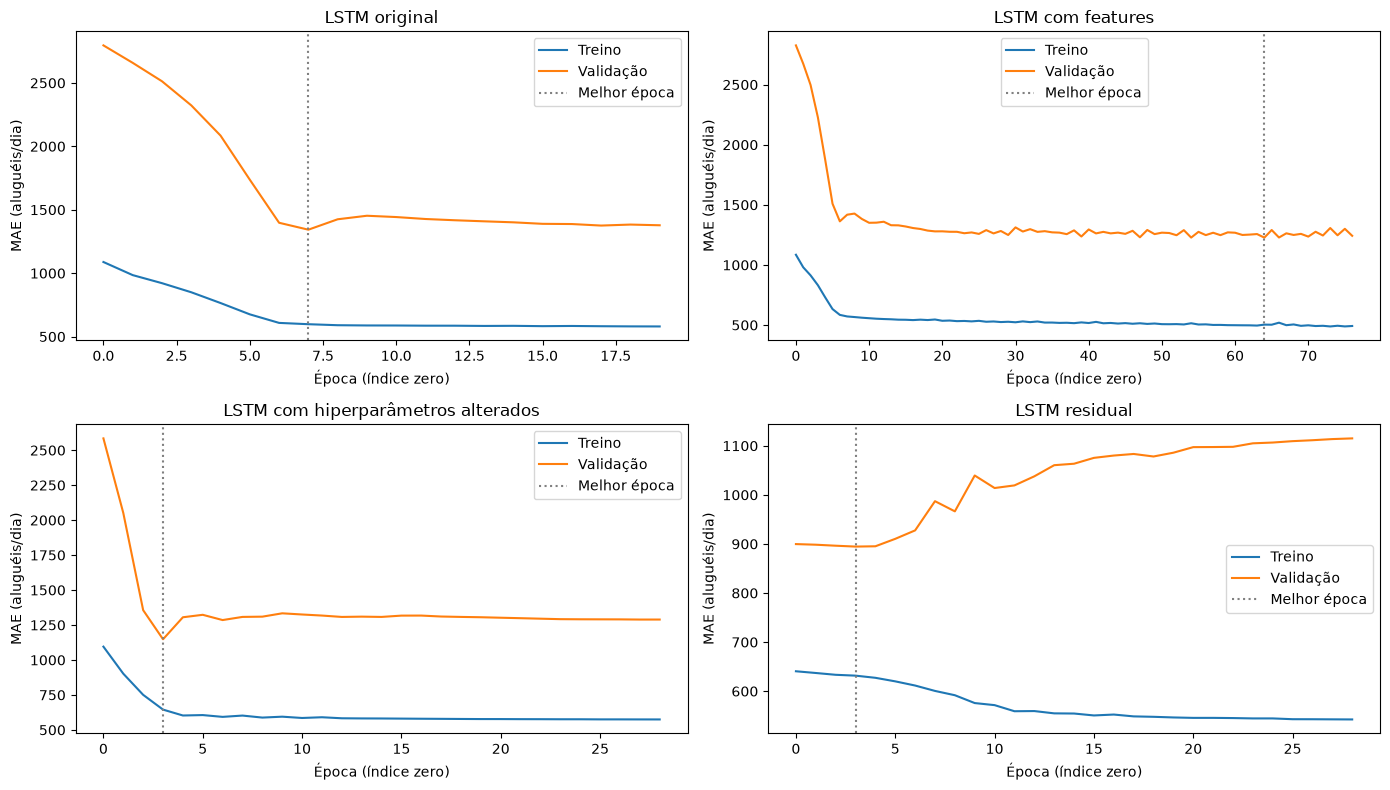

In [12]:
curvas={'LSTM original':historicos[escolhida],
        'LSTM com features':hist_features.history,**historicos_ajustados}
fig,axes=plt.subplots(2,2,figsize=(14,8))
for ax,(nome,hist) in zip(axes.flat,curvas.items()):
    ax.plot(np.asarray(hist['loss'])*desvio,label='Treino')
    ax.plot(np.asarray(hist['val_loss'])*desvio,label='Validação')
    ax.axvline(np.argmin(hist['val_loss']),color='gray',linestyle=':',label='Melhor época')
    ax.set(title=nome,xlabel='Época (índice zero)',ylabel='MAE (aluguéis/dia)')
    ax.legend()
fig.tight_layout()
plt.show()


### 8.2. Comparação final
As quatro redes usam as mesmas datas-alvo e a semente 42. As configurações permanecem fixas nesta avaliação. A tabela mostra os MAEs de treino, validação e teste, seguidos das previsões por data e da comparação do MAE de teste com persistência e sazonalidade semanal. O teste não orienta a parada do treinamento.


,modelo,janela_dias,n_features,epocas,MAE_treino,MAE_validacao,MAE_teste
0,LSTM residual,28,1.0,29.0,629.239563,894.627747,874.131775
1,Persistência,1,NaN,NaN,641.601440,900.401367,878.394531
2,Sazonal semanal,7,NaN,NaN,794.909546,1129.952393,1194.734741
3,LSTM com hiperparâmetros alterados,7,1.0,29.0,609.160156,1148.084839,1296.454346
4,LSTM com features,7,8.0,77.0,501.964935,1227.318726,1354.611450
5,LSTM original,7,1.0,20.0,591.199219,1342.928955,1481.338867


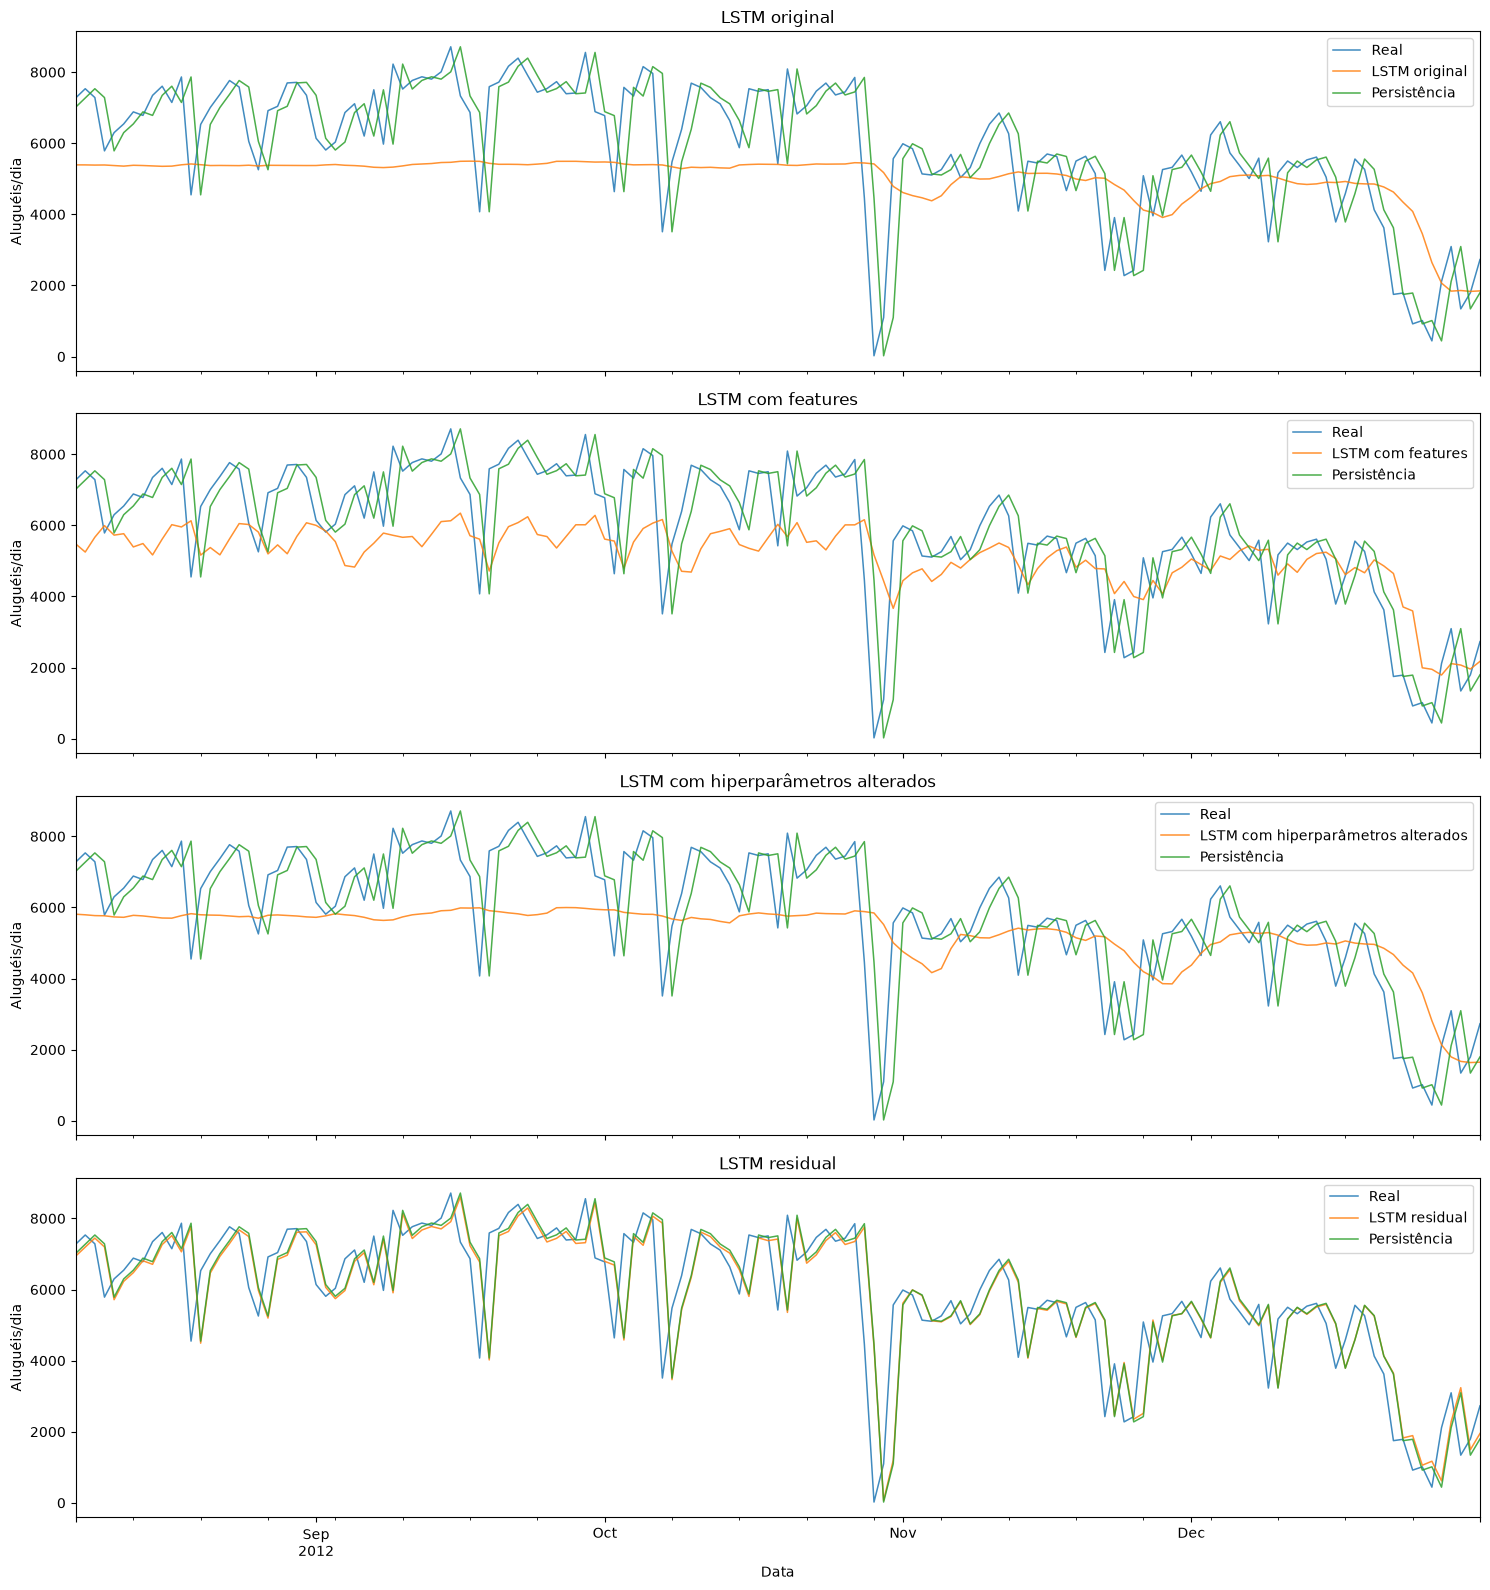

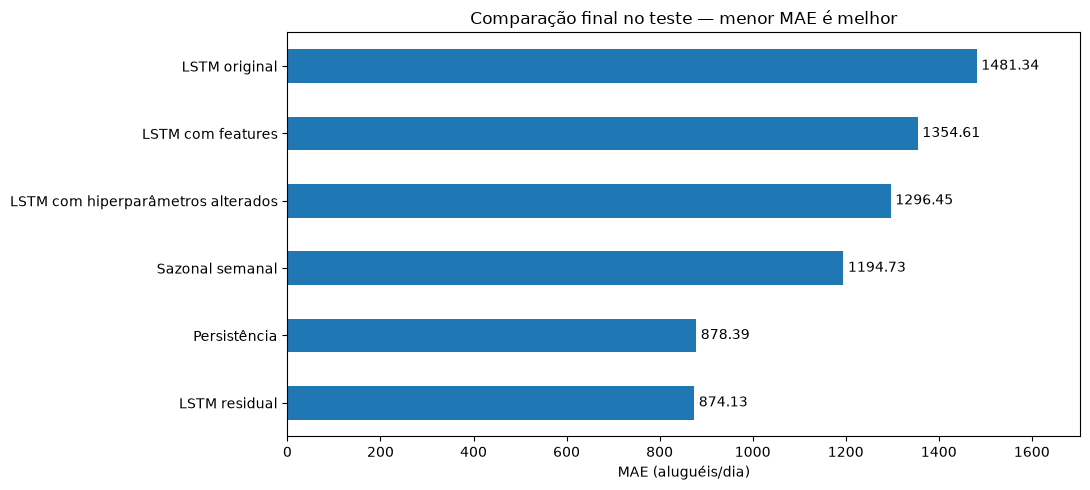

In [13]:
idx=alvos[mascaras['teste']]
redes_comparadas=[
    ('LSTM original',modelos[escolhida],dados[escolhida],escolhida,1,len(historicos[escolhida]['loss'])),
    ('LSTM com features',modelo_features,dados_features,7,8,len(hist_features.history['loss'])),
    *[(c['nome'],modelos_ajustados[c['nome']],dados[c['janela']],c['janela'],1,
       len(historicos_ajustados[c['nome']]['loss'])) for c in configs_ajustadas]]
previsoes_ajustes=pd.DataFrame({'Real':valores[idx]},index=serie.index[idx])
linhas_comparacao=[]
for nome,modelo,particoes,janela,n_features,epocas in redes_comparadas:
    erros={}
    for particao in ('treino','validacao','teste'):
        Xp,_=particoes[particao]
        pred=modelo.predict(Xp,verbose=0).ravel()*desvio+media
        erros[particao]=mae(valores[alvos[mascaras[particao]]],pred)
        if particao=='teste':
            previsoes_ajustes[nome]=pred
    linhas_comparacao.append({'modelo':nome,'janela_dias':janela,'n_features':n_features,
        'epocas':epocas,'MAE_treino':erros['treino'],
        'MAE_validacao':erros['validacao'],'MAE_teste':erros['teste']})
for nome,lag in [('Persistência',1),('Sazonal semanal',7)]:
    previsoes_ajustes[nome]=valores[idx-lag]
    erros={p:mae(valores[alvos[m]],valores[alvos[m]-lag]) for p,m in mascaras.items()}
    linhas_comparacao.append({'modelo':nome,'janela_dias':lag,'n_features':None,'epocas':None,
        'MAE_treino':erros['treino'],'MAE_validacao':erros['validacao'],'MAE_teste':erros['teste']})
comparacao_modelos=pd.DataFrame(linhas_comparacao).sort_values('MAE_teste').reset_index(drop=True)
display(comparacao_modelos)

fig,axes=plt.subplots(4,1,figsize=(15,16),sharex=True,sharey=True)
for ax,(nome,*_) in zip(axes,redes_comparadas):
    previsoes_ajustes[['Real',nome,'Persistência']].plot(ax=ax,linewidth=1.1,alpha=0.85)
    ax.set(title=nome,ylabel='Aluguéis/dia')
axes[-1].set_xlabel('Data')
fig.tight_layout()
plt.show()
ax=comparacao_modelos.plot.barh(x='modelo',y='MAE_teste',legend=False,figsize=(11,5))
ax.set(title='Comparação final no teste — menor MAE é melhor',xlabel='MAE (aluguéis/dia)',ylabel='')
for i,valor in enumerate(comparacao_modelos['MAE_teste']):
    ax.text(valor+10,i,f'{valor:.2f}',va='center')
ax.set_xlim(0,comparacao_modelos['MAE_teste'].max()*1.15)
plt.tight_layout()
plt.show()


### 8.3. Interpretação dos resultados
A análise empírica compara as configurações apresentadas, sem afirmar que são as melhores entre todas as possibilidades. A LSTM com features acrescenta informação de calendário; a ajustada aumenta a capacidade e modifica o treinamento; a residual altera a forma de prever. A melhora da residual não deve ser atribuída apenas aos hiperparâmetros.

As conclusões se limitam à execução com semente 42 e a esta divisão temporal. A diferença pequena contra a persistência deve ser explicitada. A validação e o teste são preservados, mas não se reproduz aqui o histórico de buscas de features e hiperparâmetros.


In [14]:
metricas=comparacao_modelos.set_index('modelo')
texto_final='MAE de teste: '+ '; '.join(f'{r.modelo} = {r.MAE_teste:.2f}'
                                      for r in comparacao_modelos.itertuples())+'. '
ganho_features=100*(metricas.loc['LSTM original','MAE_teste']-metricas.loc['LSTM com features','MAE_teste'])/metricas.loc['LSTM original','MAE_teste']
ganho_residual=100*(metricas.loc['LSTM original','MAE_teste']-metricas.loc['LSTM residual','MAE_teste'])/metricas.loc['LSTM original','MAE_teste']
ganho_persistencia=100*(metricas.loc['Persistência','MAE_teste']-metricas.loc['LSTM residual','MAE_teste'])/metricas.loc['Persistência','MAE_teste']
texto_final+=f'A LSTM com dia da semana e feriado reduziu o MAE em {ganho_features:.2f}% frente à original. '
texto_final+=f'A residual reduziu o MAE em {ganho_residual:.2f}% frente à original e {ganho_persistencia:.2f}% frente à persistência (negativo indica piora). '
texto_final+='As configurações foram definidas empiricamente; a comparação usa uma semente e uma divisão temporal, com teste já consultado durante a exploração. Não demonstra superioridade geral.'
display(Markdown(texto_final))


MAE de teste: LSTM residual = 874.13; Persistência = 878.39; Sazonal semanal = 1194.73; LSTM com hiperparâmetros alterados = 1296.45; LSTM com features = 1354.61; LSTM original = 1481.34. A LSTM com dia da semana e feriado reduziu o MAE em 8.55% frente à original. A residual reduziu o MAE em 40.99% frente à original e 0.49% frente à persistência (negativo indica piora). As configurações foram definidas empiricamente; a comparação usa uma semente e uma divisão temporal, com teste já consultado durante a exploração. Não demonstra superioridade geral.


## Referências
- Fanaee-T, H. Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894
- TensorFlow. LSTM: https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM
- TensorFlow. EarlyStopping: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping
- Lauda LSTM 2026_2 e Janelas de entrada para LSTM: materiais fornecidos na atividade.